|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[8] All to all cosine similarity</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch

# for monitoring for-loop progress
from tqdm import tqdm

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Background: Embeddings vectors**

In [3]:
# load BERT tokenizer and model
from transformers import BertTokenizer, BertModel

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\daler\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\daler\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [4]:
# the embeddings matrix
embeddings = model.embeddings.word_embeddings.weight.detach()

# check shape of embedding matrix (vocab size × embedding dim)
print(f'Embedding matrix shape: {embeddings.shape}')

Embedding matrix shape: torch.Size([30522, 768])


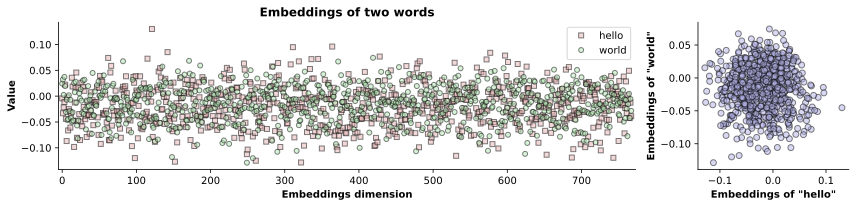

In [5]:
# two words (should be single-token)
word1 = 'hello'
word2 = 'world'

# get two token indices
token1 = tokenizer.encode(word1,add_special_tokens=False)
token2 = tokenizer.encode(word2,add_special_tokens=False)

# their embeddings vectors
emb1 = embeddings[token1,:].squeeze()
emb2 = embeddings[token2,:].squeeze()

# and plot
fig = plt.figure(figsize=(12,3))
gs = gridspec.GridSpec(1,4,figure=fig)
ax1 = fig.add_subplot(gs[:3])
ax2 = fig.add_subplot(gs[-1])

ax1.plot(emb1,'ks',markerfacecolor=[.9,.7,.7,.5],markersize=5,label=word1)
ax1.plot(emb2,'ko',markerfacecolor=[.7,.9,.7,.5],markersize=5,label=word2)

ax1.set(xlabel='Embeddings dimension',ylabel='Value',xlim=[-5,len(emb1)+5],title='Embeddings of two words')
ax1.legend()

ax2.plot(emb1,emb2,'ko',markerfacecolor=[.7,.7,.9,.5])
ax2.set(xlabel=f'Embeddings of "{word1}"',ylabel=f'Embeddings of "{word2}"')

plt.tight_layout()
plt.savefig('ch3_embeddingsA.png')
plt.show()

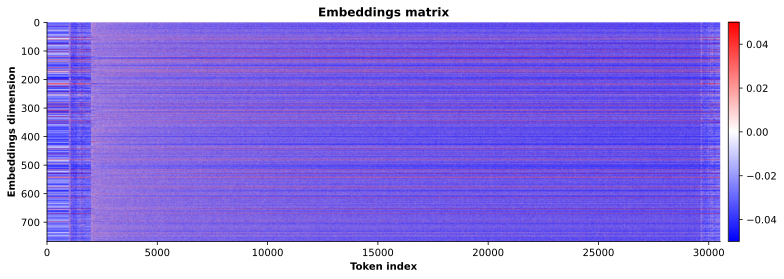

In [8]:
# the whole matrix
plt.figure(figsize=(12,4))
plt.imshow(embeddings.T,vmin=-.05,vmax=.05,aspect='auto',cmap='bwr')

plt.gca().set(xlabel='Token index',ylabel='Embeddings dimension',
              title='Embeddings matrix')

plt.colorbar(pad=.01)
plt.tight_layout()
plt.savefig('ch3_embeddingsB.png')
plt.show()

# **Background: Cosine similarity**

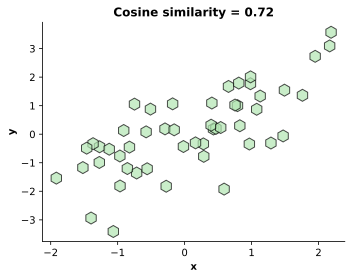

In [7]:
# generate some correlated data
x = np.random.randn(50)
y = x + np.random.randn(50)

# manual cosine similarity
num = np.sum(x*y)
norm_x = np.sum(x**2)
norm_y = np.sum(y**2)
den = np.sqrt( norm_x*norm_y )
cs = num/den

plt.figure(figsize=(5,4))
plt.plot(x,y,'kh',markerfacecolor=[.7,.9,.7,.7],markersize=12)
plt.gca().set(xlabel='x',ylabel='y',
              title=f'Cosine similarity = {cs:.2f}')

plt.tight_layout()
plt.savefig('ch3_cossimA.png')
plt.show()

In [9]:
# create a data matrix (random numbers with linear offsets)
n = 100 # observations
m = 15  # features

# create the data (try commenting out the + np.linspace...)
X = np.random.randn(n,m) + np.linspace(-2,2,m)

# normalize (note the vector_norm not matrix_norm!)
# also be careful of which axis to normalize depending on matrix dimension
X_norm = X / np.linalg.norm(X,axis=0,keepdims=True)

# cosine similarity matrix (note the transpose on the first matrix)
csM = X_norm.T @ X_norm

# correlation matrix
R = np.corrcoef(X.T)

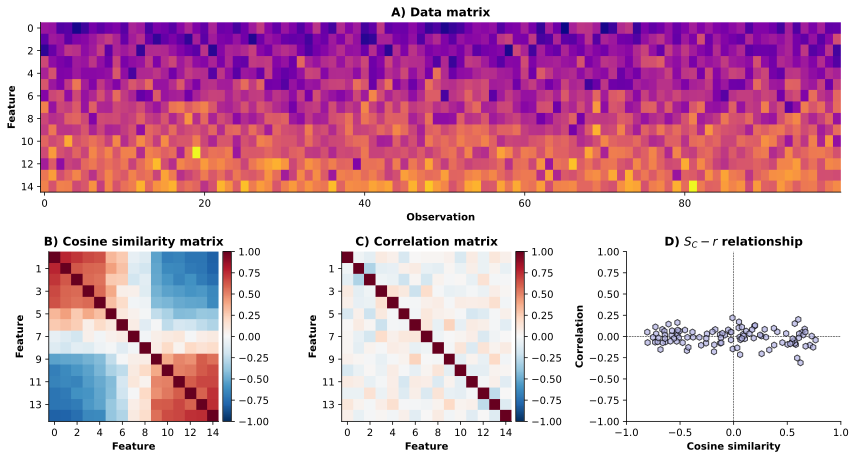

In [10]:
fig = plt.figure(figsize=(12,6.5))
gs = gridspec.GridSpec(2,3,figure=fig)
ax1 = fig.add_subplot(gs[0,:])
ax2 = fig.add_subplot(gs[1,0])
ax3 = fig.add_subplot(gs[1,1])
ax4 = fig.add_subplot(gs[1,2])


ax1.imshow(X.T,aspect='auto',cmap='plasma')
ax1.set(xlabel='Observation',ylabel='Feature',title='A) Data matrix')

# and the cosine similarity matrix
h = ax2.imshow(csM,vmin=-1,vmax=1,cmap='RdBu_r')
fig.colorbar(h,ax=ax2,pad=.02)
ax2.set(xlabel='Feature',ylabel='Feature',xticks=range(0,m,2),yticks=range(1,m,2),
           title='B) Cosine similarity matrix')

# and the cosine similarity matrix
h = ax3.imshow(R,vmin=-1,vmax=1,cmap='RdBu_r')
fig.colorbar(h,ax=ax3,pad=.02)
ax3.set(xlabel='Feature',ylabel='Feature',xticks=range(0,m,2),yticks=range(1,m,2),
           title='C) Correlation matrix')


unique_cs = csM[np.triu_indices(csM.shape[0],k=1)]
unique_rs = R[np.triu_indices(R.shape[0],k=1)]

ax4.axhline(0,linestyle='--',color='k',linewidth=.5)
ax4.axvline(0,linestyle='--',color='k',linewidth=.5)
ax4.plot(unique_cs,unique_rs,'kh',markerfacecolor=[.7,.7,.9,.7])
ax4.set(xlabel='Cosine similarity',ylabel='Correlation',xlim=[-1,1],ylim=[-1,1],
        title='D) $S_C-r$ relationship')

plt.tight_layout()
plt.savefig('ch3_cossimB.png')
plt.show()

# **Now for the project**

# **Part 1: Similarity of embeddings pairs**

In [11]:
# use this code for two random tokens
tokenpair = np.random.choice(np.arange(3000,6001),2)

In [12]:
# or pick two words
word1 = 'sunshine'
word2 = 'pineapple'

# tokenize
# tokenpair = tokenizer.encode([word1,word2],add_special_tokens=False)

In [13]:
# check that these are single-token words
for t in tokenpair:
  print(f'{t:5} is "{tokenizer.decode(t)}"')

 4081 is "suggested"
 3612 is "wind"


In [14]:
# get their embedding vectors
v1 = embeddings[tokenpair[0]]
v2 = embeddings[tokenpair[1]]

v1_token = tokenizer.decode(tokenpair[0])
v2_token = tokenizer.decode(tokenpair[1])

print(f'Token pair: "{v1_token}" and "{v2_token}"')
print(f'Embedding shape: {v1.shape}')

Token pair: "suggested" and "wind"
Embedding shape: torch.Size([768])


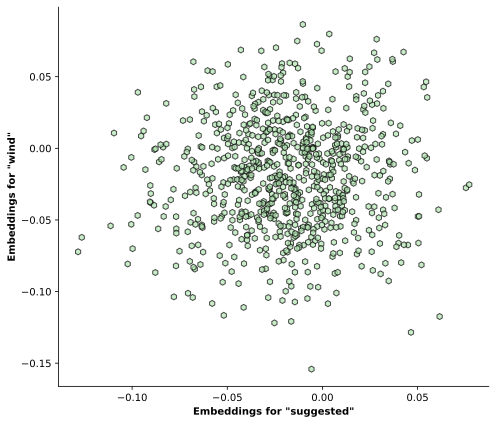

In [15]:
plt.figure(figsize=(7,6))

plt.plot(v1,v2,'kh',markerfacecolor=[.7,.9,.7,.7])
plt.gca().set(xlabel=f'Embeddings for "{v1_token}"',ylabel=f'Embeddings for "{v2_token}"')

plt.tight_layout()
plt.savefig('ch3_proj8_part1.png')
plt.show()

In [16]:
# calculate cosine similarity manually
num = torch.sum(v1*v2)
norm_v1 = torch.sqrt( torch.sum(v1**2) )
norm_v2 = torch.linalg.norm(v2) # equivalent to previous line
den = norm_v1*norm_v2

print(f'Shape of vectors: {v1.shape}')
manual_cs = num/den

Shape of vectors: torch.Size([768])


In [17]:
# and now in torch
v1_t = v1.unsqueeze(dim=0)
v2_t = v2.view(1,-1) # both view() and unsqueeze() work in this case

print(f'Shape of torch vectors: {v1_t.shape}')
torch_cs = torch.cosine_similarity(v1_t,v2_t)

Shape of torch vectors: torch.Size([1, 768])


In [18]:
# print the results
print(f'Manual cosine similarity:  {manual_cs:.5f}')
print(f'Pytorch cosine similarity: {torch_cs.item():.5f}')

Manual cosine similarity:  0.25434
Pytorch cosine similarity: 0.25434


# **Part 2: All-to-all cosine similarity**

In [19]:
# normalize (note the vector_norm not matrix_norm!)
# important: compare dim=1 here to dim=0 earlier (also note that numpy calls it "axis" instead of "dim")
E_norm = embeddings / torch.linalg.norm(embeddings,dim=1,keepdim=True)

# cosine similarity matrix (note which matrix is transposed)
csM = E_norm @ E_norm.T

# check size
print(f'Cosine similarity matrix shape: {csM.shape} ({np.prod(csM.shape):,} total elements!)')

Cosine similarity matrix shape: torch.Size([30522, 30522]) (931,592,484 total elements!)


In [20]:
# check resources (System RAM) before and after running this code block

# reduce precision to save on RAM for subsequent analyses
csM = csM.to(torch.float16)

# and delete unused large variable
del E_norm

In [21]:
# select a subset of the matrix
skip = 3
csMsub = csM[::skip,::skip]

# check size
print(f'Full matrix shape: {csM.shape} ({np.prod(csM.shape):>11,} total elements!)')
print(f'Submatrix shape  : {csMsub.shape} ({np.prod(csMsub.shape):>11,} total elements!)')

Full matrix shape: torch.Size([30522, 30522]) (931,592,484 total elements!)
Submatrix shape  : torch.Size([10174, 10174]) (103,510,276 total elements!)


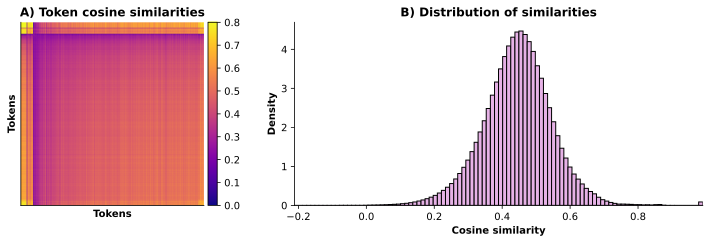

In [22]:
# get the non-redundant values of that matrix
cs_nonredun = csMsub[np.triu_indices(csMsub.shape[0],k=1)]

# show the histogram
fig,axs = plt.subplots(1,2,figsize=(12,3.5))

h = axs[0].imshow(csMsub,vmin=0,vmax=.8,cmap='plasma')
axs[0].set(title='A) Token cosine similarities',xticks=[],yticks=[],
           xlabel='Tokens',ylabel='Tokens')
plt.colorbar(h,ax=axs[0],pad=.01)

axs[1].hist(cs_nonredun,bins=100,density=True,color=[.9,.7,.9],edgecolor='k')
axs[1].set(xlabel='Cosine similarity',ylabel='Density',
           xlim=[cs_nonredun.min(),cs_nonredun.max()],
           title='B) Distribution of similarities')

plt.tight_layout()
plt.savefig('ch3_proj8_part2.png')
plt.show()

# **Part 3: BERT's unused tokens**

In [23]:
for i in range(20):
  print(f'Token {i:2} is "{tokenizer.decode(i)}"')

Token  0 is "[PAD]"
Token  1 is "[unused0]"
Token  2 is "[unused1]"
Token  3 is "[unused2]"
Token  4 is "[unused3]"
Token  5 is "[unused4]"
Token  6 is "[unused5]"
Token  7 is "[unused6]"
Token  8 is "[unused7]"
Token  9 is "[unused8]"
Token 10 is "[unused9]"
Token 11 is "[unused10]"
Token 12 is "[unused11]"
Token 13 is "[unused12]"
Token 14 is "[unused13]"
Token 15 is "[unused14]"
Token 16 is "[unused15]"
Token 17 is "[unused16]"
Token 18 is "[unused17]"
Token 19 is "[unused18]"


In [24]:
# find the "unused" tokens
unused_tokens = torch.zeros(tokenizer.vocab_size,dtype=bool)
for i in range(tokenizer.vocab_size):
  if '[unused' in tokenizer.decode(i):
    unused_tokens[i] = True

titleinfo = f'{unused_tokens.sum()}/{tokenizer.vocab_size} ({100*unused_tokens.sum()/tokenizer.vocab_size:.2f}%) "unused" tokens'

# visualize
plt.figure(figsize=(10,3))
plt.plot(range(tokenizer.vocab_size),torch.randn(tokenizer.vocab_size)/40+unused_tokens,
         'ko',markersize=2,markerfacecolor='w',alpha=.3)
plt.gca().set(xlabel='Token index',ylabel='Value',yticks=[0,1],yticklabels=['Used','Unused'],ylim=[-.5,1.5],
              xlim=[-15,len(unused_tokens)+15],title=titleinfo)

plt.tight_layout()
plt.savefig('ch3_proj8_part3.png')
plt.show()

In [25]:
# extract a submatrix of just the unused tokens
csMsub = csM[unused_tokens,:][:,unused_tokens]

# get the unique values of that matrix
cs_nonredun = csMsub[np.triu_indices(csMsub.shape[0],k=1)]
cs_unique = np.unique(cs_nonredun)

print(f'There are {cs_nonredun.shape[0]:,} non-redundant values, {len(cs_unique)} of which are unique.')
print('\nThe unique values are:\n',cs_unique)

There are 493,521 non-redundant values, 13 of which are unique.

The unique values are:
 [0.9854 0.986  0.9863 0.987  0.9873 0.988  0.9883 0.989  0.9893 0.9897
 0.99   0.9907 0.991 ]


# **Part 4: GPT2 all to all, done differently**

In [26]:
# GPT2 tokenizer and model
from transformers import GPT2Model
model = GPT2Model.from_pretrained('gpt2')

# the embeddings matrix
embeddings = model.wte.weight.detach()

# downsample and reduce the precision before calculations
skip = 5
embeddings = embeddings[::skip,:].to(torch.float16)
embeddings.shape

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\daler\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\daler\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

torch.Size([10052, 768])

In [27]:
# normalize in a different way
E_norm = torch.nn.functional.normalize(embeddings,p=2,dim=1)

# initialize block size and CS matrix
N = embeddings.shape[0]
block = 1024
csM = torch.empty(N,N,dtype=E_norm.dtype)

# loop over blocks
for i in tqdm(range(0,N,block)):

  # find end index
  end_i = min(i+block,N)

  # calculate just this block of cossim and put into matrix
  cs_part = E_norm[i:end_i] @ E_norm.T
  csM[i:end_i] = cs_part

100%|██████████| 10/10 [00:04<00:00,  2.39it/s]


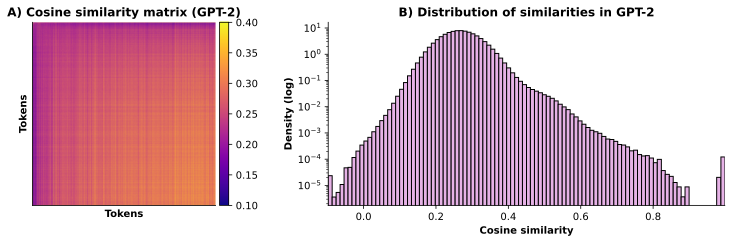

In [28]:
# get the non-redundant values of that matrix
row,col = np.triu_indices(csM.shape[0], k=1)
cs_nonredun = csM[row,col]

# show the histogram
fig,axs = plt.subplots(1,2,figsize=(12,3.5))

h = axs[0].imshow(csM,vmin=.1,vmax=.4,cmap='plasma')
axs[0].set(title='A) Cosine similarity matrix (GPT-2)',xticks=[],yticks=[],
           xlabel='Tokens',ylabel='Tokens')
plt.colorbar(h,ax=axs[0],pad=.01)

axs[1].hist(cs_nonredun,bins=100,density=True,color=[.9,.7,.9],edgecolor='k')
axs[1].set(xlabel='Cosine similarity',ylabel='Density (log)',
           xlim=[cs_nonredun.min(),cs_nonredun.max()],yscale='log',
           title='B) Distribution of similarities in GPT-2')

plt.tight_layout()
plt.savefig('ch3_proj8_part4.png')
plt.show()

# **Part 5: Compare correlation and similarity**

In [29]:
# mean-center and variance-normalize
E_norm = embeddings - embeddings.mean(dim=1,keepdim=True)
E_norm = torch.nn.functional.normalize(E_norm,p=2,dim=1)

R = torch.empty(N,N,dtype=E_norm.dtype)

# loop over blocks
for i in tqdm(range(0,N,block)):

  # find end index
  end_i = min(i+block,N)

  # calculate just this block of correlation and put into matrix
  R_part = E_norm[i:end_i] @ E_norm.T
  R[i:end_i] = R_part


# extract non-redundant matrix elements
R_nonredun = R[row,col]

100%|██████████| 10/10 [00:03<00:00,  2.54it/s]


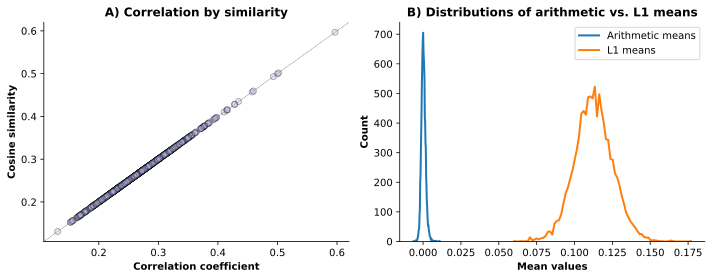

In [30]:
# calculate histograms
yAr,xAr = np.histogram(embeddings.mean(dim=1).numpy(),bins=80) # convert to numpy (not actually necessary here)
yL1,xL1 = np.histogram(abs(embeddings).mean(dim=1),bins=80)


fig,axs = plt.subplots(1,2,figsize=(10,4))

# show the scatter plot
skip = 50000
# line of unity
axs[0].axline(np.full(2,R_nonredun[::skip].min().item()),slope=1,
              color='k',linestyle='--',linewidth=.3)
# scatter
axs[0].plot(R_nonredun[::skip],cs_nonredun[::skip],'ko',markerfacecolor=[.7,.7,.9,.3])
axs[0].set(xlabel='Correlation coefficient',ylabel='Cosine similarity',
           title='A) Correlation by similarity')

# and the histograms
axs[1].plot(xAr[:-1],yAr,linewidth=2,label='Arithmetic means')
axs[1].plot(xL1[:-1],yL1,linewidth=2,label='L1 means')
axs[1].legend()
axs[1].set(xlabel='Mean values',ylabel='Count',ylim=[0,None],
           title='B) Distributions of arithmetic vs. L1 means')

plt.tight_layout()
plt.savefig('ch3_proj8_part5.png')
plt.show()